In [28]:
import pandas as pd

In [29]:
my_headers = ["ID", "UK", "GQ"]
F1=pd.read_table("F1_quality.txt",
              sep="\t",
              skiprows=[0], 
              usecols=range(3),
              header=None,
              names=my_headers)

In [30]:
F1

,ID,UK,GQ
0,chr1-11991-SNV->19342<19344>19346-1,0,GQ: 55
1,chr1-12566-DEL->19398>19401-1,60,GQ: 55
2,chr1-12569-DEL->19402>19404-2,60,GQ: 91
3,chr1-12766-SNV->19427<19428>19430-1,18,GQ: 55
4,chr1-12822-SNV->19436>19437>19439-1,18,GQ: 90
...,...,...,...
4600678,chrX-154253812-SNV->83804843>83804841>83804840-1,301,GQ: 88
4600679,chrX-154254188-SNV->83804763<83804761>83804760-1,301,GQ: 88
4600680,chrX-154254305-SNV->83804739>83804737>83804736-1,301,GQ: 88
4600681,chrX-154255726-SNV->83804387<83804385>83804384-1,301,GQ: 10000


In [31]:
F1['GQ']=F1['GQ'].str[3:].astype(int)

In [32]:
F1['UK']=F1['UK'].astype(int)

## 1. Loading in and understanding the data

We start by loading the entire variant genotyping set from PanGenie for F1 to see what appropriate filtration criteria should be. Ideally, we would remove a hits falling below a certain percentile in the GQ, if we're doing something analogous to QUAL in a traditional variant calling set.

In [33]:
F1

,ID,UK,GQ
0,chr1-11991-SNV->19342<19344>19346-1,0,55
1,chr1-12566-DEL->19398>19401-1,60,55
2,chr1-12569-DEL->19402>19404-2,60,91
3,chr1-12766-SNV->19427<19428>19430-1,18,55
4,chr1-12822-SNV->19436>19437>19439-1,18,90
...,...,...,...
4600678,chrX-154253812-SNV->83804843>83804841>83804840-1,301,88
4600679,chrX-154254188-SNV->83804763<83804761>83804760-1,301,88
4600680,chrX-154254305-SNV->83804739>83804737>83804736-1,301,88
4600681,chrX-154255726-SNV->83804387<83804385>83804384-1,301,10000


In [48]:
F1_notSNV = F1[~F1.ID.str.contains('SNV')]

In [49]:
F1_notSNV

,ID,UK,GQ
1,chr1-12566-DEL->19398>19401-1,60,55
2,chr1-12569-DEL->19402>19404-2,60,91
18,chr1-15891-INS->19648>19649>19650-1,59,55
21,chr1-17625-DEL->19785>19788-1,12,55
36,chr1-23005-INS->20239<20240<20241>20242-20,69,55
...,...,...,...
4600672,chrX-154242483-DEL->84704139>84704141-1,6,92
4600673,chrX-154243866-INS->84704190<84704196<84704197...,1,84
4600674,chrX-154244326-DEL->84704222>84704225-1,12,81
4600675,chrX-154244326-DEL->84704222>84704226-2,12,81


In [53]:
F1_reasonable = F1_notSNV[F1_notSNV['GQ']<50]

In [54]:
F1_reasonable

,ID,UK,GQ
302,chr1-58494-COMPLEX->25237>25238>25240>25244-2,61,4
303,chr1-58496-COMPLEX->25241<25242>25246-6,61,4
314,chr1-59640-COMPLEX->25319>25320>25322-2,29,10
318,chr1-60640-INS->25383>25385>25387>25388>25389-6,36,2
319,chr1-60645-DEL->25392>25397-2,36,2
...,...,...,...
4600629,chrX-154101349-INS->84700569<84700572<84700573...,29,3
4600632,chrX-154115930-DEL->84700875>84700878-1,0,3
4600640,chrX-154158486-DEL->84701704>84701706-1,128,49
4600646,chrX-154161819-COMPLEX->84701790>84701791>8470...,17,34


In [81]:
F1_reallygood = F1[F1['GQ']>=9000]
F1_reallygood

,ID,UK,GQ
8,chr1-14458-SNV->19548<19549>19551-1,62,10000
13,chr1-14726-SNV->19578<19579>19581-1,31,10000
25,chr1-18711-SNV->19923<19924>19926-1,0,10000
28,chr1-19996-SNV->19989<19990>19992-1,62,10000
31,chr1-21367-SNV->20065<20066>20069-1,92,10000
...,...,...,...
4600665,chrX-154222437-INS->84703254<84703256>84703257-1,38,10000
4600666,chrX-154227873-SNV->84703442<84703443>84703445-1,65,10000
4600668,chrX-154228689-SNV->84703489<84703490>84703492-1,62,10000
4600671,chrX-154241646-SNV->84704103<84704104>84704106-1,31,10000


In [113]:
F1_ins = F1[F1.ID.str.contains('INS')]

## 2. Explaining the distribution of genotype quality

Notably, there are lots of records that have unusually high GQ. Taken on a Phred score, there are a lot of high confidence scores (e.g. GQ>50) and a lot of anomalously high GQ hits (GQ=10000).

I couldn't find documentation on the anomalous GQ hits--my suspicion is that this represents some sort of error code in PanGenie. But we should look for explanatory factors. One obvious contributor to GQ is the number of unique kmers that map to the given variant. A variant with many unique kmers is less repetitive and has greater support of informative reads that distinguish it from other haplotypes in the PanGenie reference haplotype set. If the GQ distribution matches the UK distribution, this lends some credence to the idea that high UK directly causes high GQ.

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
def plot_uk_distribution(df, title="UK Distribution"):
    df_copy = df.copy()
    
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.histplot(y=df_copy["UK"].sample(100000), ax=ax)
    ax.set_title(title)
    
    plt.savefig(f"/Users/aarontran/Desktop/wanglab/quality_files/{title.replace(' ', '_')}.png", dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
    plt.show()

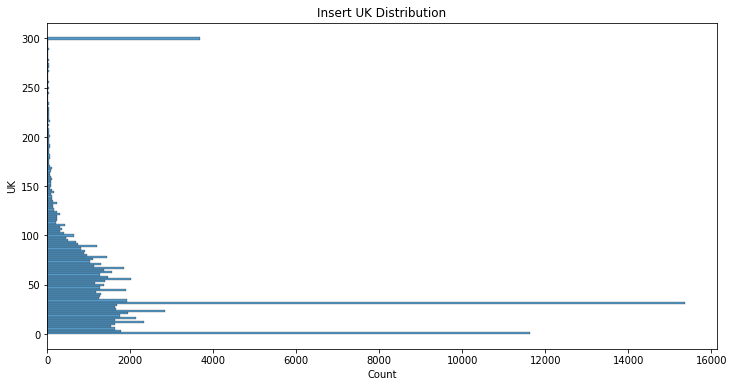

In [114]:
plot_uk_distribution(F1_ins, title="Insert UK Distribution")

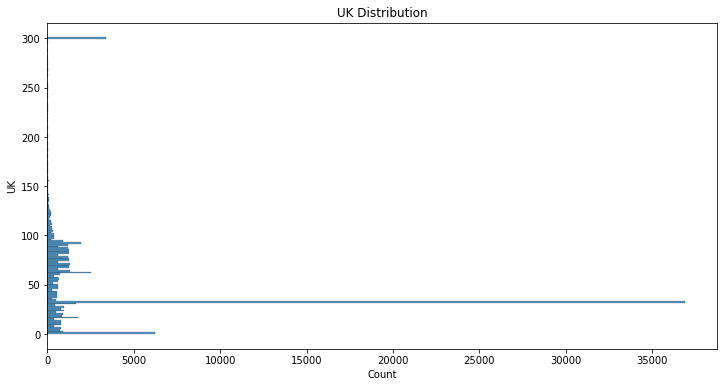

In [115]:
plot_uk_distribution(F1, title="UK Distribution")

In [101]:
F1['UK'].value_counts()[:5].index.tolist()

[32, 0, 301, 62, 16]

In [60]:
def plot_gq_distribution(df, title="GQ Distribution"):
    df_copy = df.copy()
    
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.histplot(y=df_copy["GQ"].sample(100000), ax=ax)
    ax.set_title(title)
    
    plt.savefig(f"/Users/aarontran/Desktop/wanglab/quality_files/{title.replace(' ', '_')}.png", dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
    plt.show()

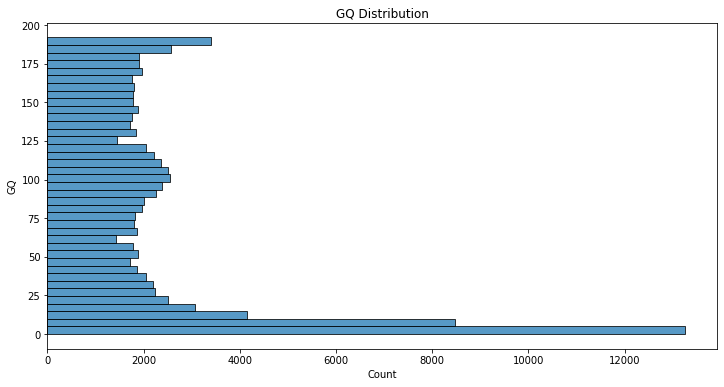

In [117]:
plot_gq_distribution(F1[F1['GQ']<200])

In [78]:
def plot_cdf_distribution(df, title="CDF Distribution"):
    df_copy = df.copy()
    
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.ecdfplot(x=df_copy["GQ"].sample(100000), ax=ax)
    ax.set_title(title)
    
    plt.savefig(f"/Users/aarontran/Desktop/wanglab/quality_files/{title.replace(' ', '_')}.png", dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
    plt.show()

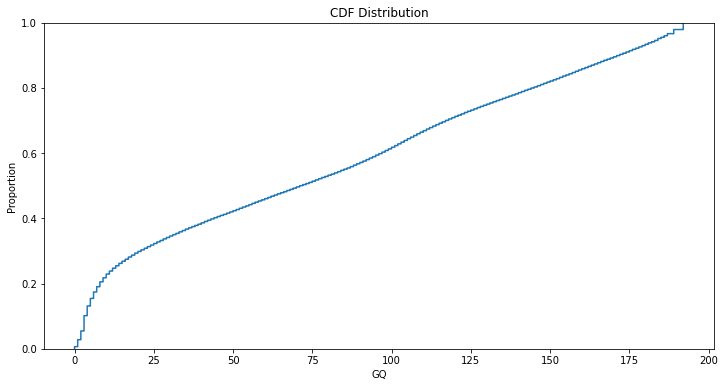

In [79]:
plot_cdf_distribution(F1[F1['GQ']<200])

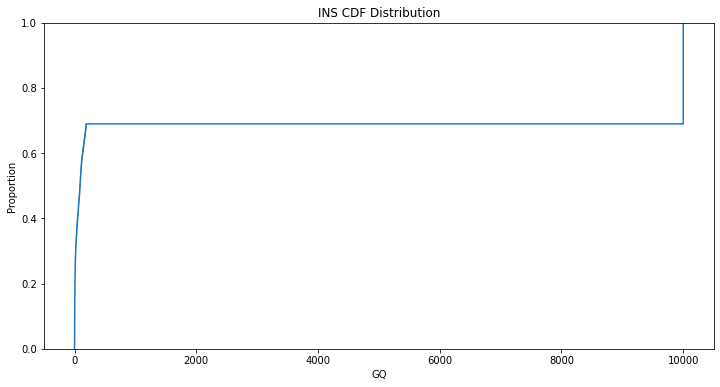

In [119]:
plot_cdf_distribution(F1_ins, title="INS CDF Distribution")

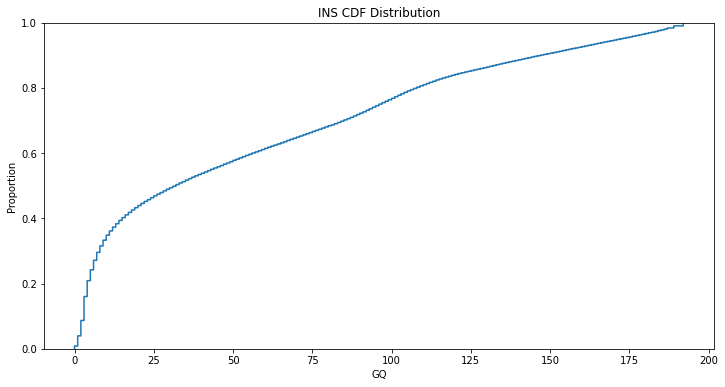

In [120]:
plot_cdf_distribution(F1_ins[F1_ins['GQ'] < 200], title="INS CDF Distribution")

## 3. Trying to find factors more clearly

The distributions plotted above show that the UK distribution doesn't really neatly mirror the GQ distribution. Traditionally, GQ-like (i.e. QUAL) distributions have a short tail at the low quality left end, a peak at a decent quality range, and a long tail of high quality calls. Instead, most of our genotype calls have a remarkably low GQ. Interestingly, the *kmer* distribution seems to have a little more of the shape we expected.

I suspect that GQ filtration should be calibrated differently than our traditional intuitions for variant calling. Look at the CDF distribution of GQ in inserts above--there is no clean "jump" in quality, but rather a big peak at low GQ that then increases steadily. There is no discontinuity.

The other CDF above it shows the sudden peak at 10,000, indicating that this is not a continuous statistical artifact of high GQ calls but a specific artifact at 10,000. That probably reflects a *specific* design choice in PanGenie.

Let's try setting up some scatterplots to see if there's an association.

In [89]:
def plot_gq_uk_scatter(df, title="GQ vs UK"):
    df_copy = df.copy()
    
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.scatterplot(data=df_copy.sample(1000), x="UK", y="GQ", ax=ax)
    ax.set_title(title)
    
    plt.savefig(f"/Users/aarontran/Desktop/wanglab/quality_files/{title.replace(' ', '_')}.png", dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
    plt.show()

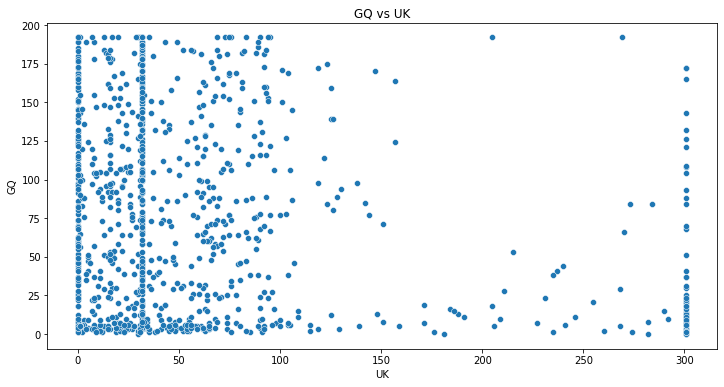

In [126]:
plot_gq_uk_scatter(F1[(F1['GQ']<200)])

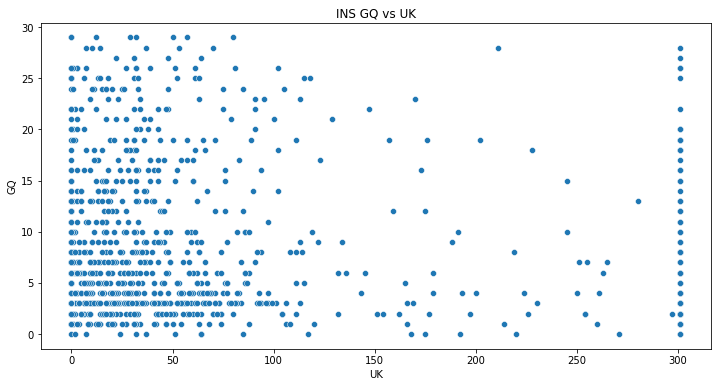

In [128]:
plot_gq_uk_scatter(F1_ins[(F1_ins['GQ']<30)], title="INS GQ vs UK")

In [134]:
F1[(F1['GQ']>=50) & (F1.ID.str.contains('INS') | F1.ID.str.contains('DEL'))]

,ID,UK,GQ
1,chr1-12566-DEL->19398>19401-1,60,55
2,chr1-12569-DEL->19402>19404-2,60,91
18,chr1-15891-INS->19648>19649>19650-1,59,55
21,chr1-17625-DEL->19785>19788-1,12,55
36,chr1-23005-INS->20239<20240<20241>20242-20,69,55
...,...,...,...
4600672,chrX-154242483-DEL->84704139>84704141-1,6,92
4600673,chrX-154243866-INS->84704190<84704196<84704197...,1,84
4600674,chrX-154244326-DEL->84704222>84704225-1,12,81
4600675,chrX-154244326-DEL->84704222>84704226-2,12,81


In [133]:
F1[(F1['GQ']>=30) & (F1.ID.str.contains('INS') | F1.ID.str.contains('DEL'))]

,ID,UK,GQ
1,chr1-12566-DEL->19398>19401-1,60,55
2,chr1-12569-DEL->19402>19404-2,60,91
18,chr1-15891-INS->19648>19649>19650-1,59,55
21,chr1-17625-DEL->19785>19788-1,12,55
36,chr1-23005-INS->20239<20240<20241>20242-20,69,55
...,...,...,...
4600672,chrX-154242483-DEL->84704139>84704141-1,6,92
4600673,chrX-154243866-INS->84704190<84704196<84704197...,1,84
4600674,chrX-154244326-DEL->84704222>84704225-1,12,81
4600675,chrX-154244326-DEL->84704222>84704226-2,12,81


## Takeaway

There aren't very clear criteria for GQ filtration in PanGenie yet, and you'll probably just want to set a "reasonable" GQ filtration criterion depending on your downstream tasks.

Furthermore, UK doesn't really explain it. This makes sense--PanGenie uses an HMM model that is leveraging lots of linkage information from nearby variants that we don't get access to. It's possible that unique kmers are piling up in nearby variants in close linkage with a high GQ variant that we can't naively check.

As it happens, I ended up overlapping my genotypes with a validated set of known transposable elements and performing a breakpoint analysis. Weirdly, GQ didn't meaningfully predict performance on the breakpoint analysis task because most of the PanGenie genotypes were just straight up correct. The PanGenie paper seems to support this too, as their variant concordance on a held out variant set is extremely good even when including variants with all GQs, not just high GQ.

My PI and Dr. Macias also discussed at lab meeting about the trouble in evaluating the "ranking" of different genotype calls--what makes a GQ100 call better than a GQ50 call? So don't be surprised if you're having issues interpreting GQ, as the architecture of the algorithm and its unusual effectiveness render this question moot, in my opinion. Much better to have downstream validation steps that are related to your downstream task of interest.